In [2]:
import numpy as np
import scipy
import scipy.linalg
import random
import math
import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import qr, svd
from tqdm import tqdm

In [3]:
def H(num):
    H = np.diag(np.ones(num-1),-1)+np.diag(np.ones(num-1),1)
    H[num-1,0]=H[0,num-1]=1

    return H

def normalize(U):
    L, N = U.shape
    V=np.empty((L,N),dtype=np.complex_)
    for j in range(N):
        V[:,j]=U[:,j]
        for k in range(j):
            V[:,j]=V[:,j]-np.vdot(U[:,j],V[:,k])*V[:,k]
        V[:,j]=V[:,j]/np.linalg.norm(V[:,j])
    return V 


In [17]:
H(50).shape

(50, 50)

In [25]:
eigval,eigvec = np.linalg.eig(H(50))
site = np.eye(50)
neel = np.zeros(50)
neel[::2]=1

In [82]:
import numpy as np
from tqdm import tqdm

# Define time and initialize n1
time = np.linspace(0, 10, 1000)
n1 = np.zeros( len(time), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 0])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1

for t in tqdm(range(len(time))):
    sum_result = 0
    
    # Precompute the exponential terms for the current time step
    # Use element-wise multiplication to compute the complex exponential
    for j in range(50):
        A = dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
        B = dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
        
        # Compute the exponential for each combination of alpha and beta
        exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
        
        # Sum over alpha and beta using vectorized numpy operations
        sum_result += np.sum(A[:, None] * B[None, :] * exp_term) * neel[j]
    
    n1[t] = sum_result


  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [00:07<00:00, 131.31it/s]


c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\aniru\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


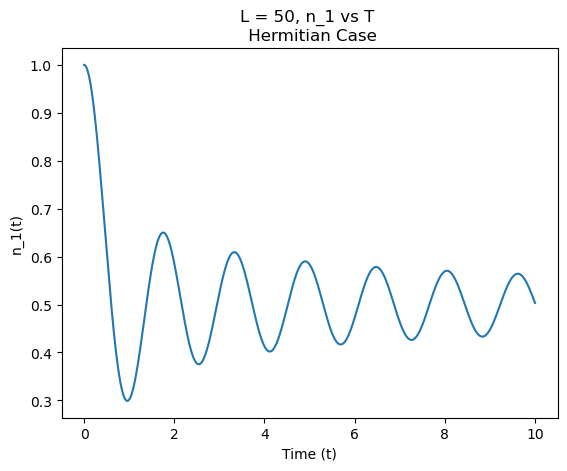

In [83]:
plt.plot(time,n1)

plt.xlabel('Time (t)')
plt.ylabel('n_1(t)')
plt.title('L = 50, n_1 vs T \n Hermitian Case')
plt.show()

In [ ]:
neel = [1 if i%2==0 else 0 for i in range(0,50)]
time= np.linspace(0,50,1000)
a = np.eye(50)
eigenvalues,eigenvectors = np.linalg.eig(H(50))

from tqdm import tqdm
val2= []
for t1 in tqdm(time):
    val= []
    for beta in range(0,50):
        for alpha in range(0,50):
            for j in range(0,50):
                valu =np.dot(eigenvectors[alpha],a[0])*np.dot(a[j],eigenvectors[alpha])*np.dot(eigenvectors[beta],a[j])*np.dot(a[0],eigenvectors[beta])*np.exp(1j*(eigenvalues[alpha]-eigenvalues[beta])*t1)*neel[j]
                val.append(valu)
    val2.append(np.real(np.sum(val)))
            
plt.figure(figsize=(5, 5))
plt.plot(time,val2)
plt.xlabel('Time (t)')
plt.ylabel('$n_i(t)$')
plt.title('Plot of evolution of neel state')
plt.show()

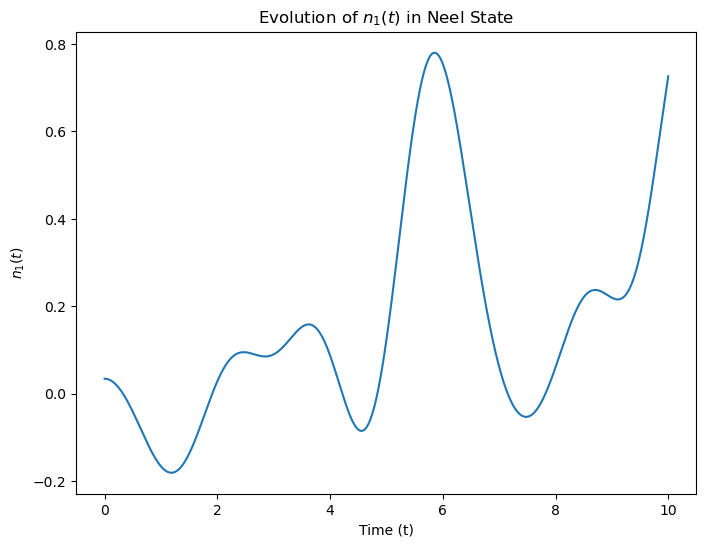

In [84]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 50  # Number of sites/eigenstates
time = np.linspace(0, 10, 1000)  # Time points
neel_state = np.array([0 if i % 2 == 0 else 1 for i in range(N)])  # Neel state

eigenvalues,eigenvectors = np.linalg.eig(H(50))
# Reshape eigenvectors for convenience: shape (N_sites, N_eigenstates)
Phi = eigenvectors
Phi_dagger = Phi.conj().T  # Hermitian conjugate

# Function to compute time evolution for n_1(t)
def compute_n1(t, Phi, Phi_dagger, eigenvalues, neel_state):
    T_t = np.exp(1j * (eigenvalues[:, None] - eigenvalues[None, :]) * t)  # Time evolution matrix
    Phi_Phi_neel = (Phi @ neel_state) * (Phi @ neel_state).conj()  # \Phi^\dagger \mathbf{n}
    
    # n_1(t) matrix expression
    n_1_t = np.sum(
        np.outer(Phi_dagger[:, 0], Phi_dagger[:, 0]) * T_t * Phi_Phi_neel
    )
    
    return np.real(n_1_t)

# Compute n_1(t) over time
n1_values = np.array([compute_n1(t, Phi, Phi_dagger, eigenvalues, neel_state) for t in time])

# Plot the result
plt.figure(figsize=(8, 6))
plt.plot(time, n1_values)
plt.xlabel('Time (t)')
plt.ylabel('$n_1(t)$')
plt.title('Evolution of $n_1(t)$ in Neel State')
plt.show()


In [91]:
eigval,eigvec = np.linalg.eig(H(50))
neel = np.array([1 if i % 2 == 0 else 0 for i in range(N)])  # Neel state


In [111]:
a = np.array([1,2,3])
b = np.array([[1,3,4],[2,3,4],[4,5,6]])

a[:,None]*b

array([[ 1,  3,  4],
       [ 4,  6,  8],
       [12, 15, 18]])

In [114]:
#eigvec.T[0] is the projection of all the alphas on the side 0
p1 = neel[:,None]*eigvec.T
eigvec@p1

array([[ 0.32008803,  0.1359666 ,  0.10266059, ..., -0.07215187,
         0.10240746,  0.13404336],
       [ 0.1359666 ,  0.56200838, -0.0959031 , ...,  0.05646839,
         0.15674194, -0.13925977],
       [ 0.10266059, -0.0959031 ,  0.50059548, ...,  0.1213643 ,
        -0.18519883,  0.15866517],
       ...,
       [-0.07215187,  0.05646839,  0.1213643 , ...,  0.52662831,
         0.02376715,  0.04048397],
       [ 0.10240746,  0.15674194, -0.18519883, ...,  0.02376715,
         0.49983176, -0.09485044],
       [ 0.13404336, -0.13925977,  0.15866517, ...,  0.04048397,
        -0.09485044,  0.56175525]])

In [102]:
np.linalg.eig(np.array([[1,2,3],[0,5,1],[3,0,2]]))

EigResult(eigenvalues=array([-1.38269994,  3.67385014,  5.7088498 ]), eigenvectors=array([[ 0.74415039, -0.4069357 , -0.58159057],
       [ 0.10339846,  0.54996857, -0.66365924],
       [-0.65996133, -0.72934074, -0.47043472]]))

In [98]:
eigenvec.T[1]

array([ 0.2       , -0.19371663,  0.17526134, -0.14579373,  0.10716536,
       -0.0618034 ,  0.0125581 ,  0.03747626, -0.08515586,  0.1274848 ,
       -0.1618034 ,  0.1859553 , -0.19842294,  0.19842294, -0.1859553 ,
        0.1618034 , -0.1274848 ,  0.08515586, -0.03747626, -0.0125581 ,
        0.0618034 , -0.10716536,  0.14579373, -0.17526134,  0.19371663,
       -0.2       ,  0.19371663, -0.17526134,  0.14579373, -0.10716536,
        0.0618034 , -0.0125581 , -0.03747626,  0.08515586, -0.1274848 ,
        0.1618034 , -0.1859553 ,  0.19842294, -0.19842294,  0.1859553 ,
       -0.1618034 ,  0.1274848 , -0.08515586,  0.03747626,  0.0125581 ,
       -0.0618034 ,  0.10716536, -0.14579373,  0.17526134, -0.19371663])

In [41]:
eigenval[:, None] + eigenval[None, :] 

array([[-4.        , -3.93716632, -3.85955297, ..., -0.72515202,
        -0.54206275, -0.72515202],
       [-3.93716632, -3.87433264, -3.79671929, ..., -0.66231834,
        -0.47922907, -0.66231834],
       [-3.85955297, -3.79671929, -3.71910594, ..., -0.58470499,
        -0.40161572, -0.58470499],
       ...,
       [-0.72515202, -0.66231834, -0.58470499, ...,  2.54969596,
         2.73278523,  2.54969596],
       [-0.54206275, -0.47922907, -0.40161572, ...,  2.73278523,
         2.91587451,  2.73278523],
       [-0.72515202, -0.66231834, -0.58470499, ...,  2.54969596,
         2.73278523,  2.54969596]])

In [50]:
A =np.array([1,2,3,4,5])
B = np.array([6,7,8,9,10])

C= (A[:,None] +B[None,:]).reshape((25))

(C[:,None] - C[None,:]).shape

(25, 25)

In [55]:
d = A[:,None] *B[None,:]

In [57]:
d[:, None, :, None].shape

(5, 1, 5, 1)

In [51]:
np.outer(A,B)

array([[ 6,  7,  8,  9, 10],
       [12, 14, 16, 18, 20],
       [18, 21, 24, 27, 30],
       [24, 28, 32, 36, 40],
       [30, 35, 40, 45, 50]])

In [70]:
eigenval,eigenvec = np.linalg.eig(H(50))
n = np.zeros(50)
n[::2]=1

In [71]:
exp_term = np.exp(1j * ((eigenval[:, None] - eigenval[None, :]).reshape(2500)[:,None] + (eigenval[:, None] -eigenval[None, :]).reshape(2500)[None,:]))

In [80]:
exp_term

array([[1.        +0.00000000e+00j, 0.99802661-6.27923406e-02j,
        0.99015352-1.39985755e-01j, ..., 1.        +2.22044605e-15j,
        0.98328593-1.82068078e-01j, 1.        +0.00000000e+00j],
       [0.99802661-6.27923406e-02j, 0.99211424-1.25336854e-01j,
        0.97940953-2.01883566e-01j, ..., 0.99802661-6.27923406e-02j,
        0.96991304-2.43451613e-01j, 0.99802661-6.27923406e-02j],
       [0.99015352-1.39985755e-01j, 0.97940953-2.01883566e-01j,
        0.96080798-2.77214776e-01j, ..., 0.99015352-1.39985755e-01j,
        0.94811708-3.17921371e-01j, 0.99015352-1.39985755e-01j],
       ...,
       [1.        +2.22044605e-15j, 0.99802661-6.27923406e-02j,
        0.99015352-1.39985755e-01j, ..., 1.        +4.44089210e-15j,
        0.98328593-1.82068078e-01j, 1.        +2.22044605e-15j],
       [0.98328593-1.82068078e-01j, 0.96991304-2.43451613e-01j,
        0.94811708-3.17921371e-01j, ..., 0.98328593-1.82068078e-01j,
        0.93370243-3.58049959e-01j, 0.98328593-1.82068078e-01j]

In [69]:
import numpy as np

# Assuming 'eigenval', 'eigenvec', 'site', and 'n' are already defined with appropriate sizes

# Size of the system (50 in this case)
size = 50

time = np.linspace(0, 10, 1000)

# Initialize result array
sum1 = np.zeros(size, dtype=np.complex128)
site = np.eye(size)

# Precompute dot products that don't depend on alpha/beta/delta/eta
dot_eigenvec_site0 = np.dot(eigenvec.T, site[0])  # Shape (50,)
dot_eigenvec_site = np.dot(site.T, eigenvec)      # Shape (50, 50)
A = np.outer(dot_eigenvec_site0, dot_eigenvec_site0).reshape(2500)  # Shape (50, 50)
B = A.copy()  # B is identical to A
exp_term = np.exp(1j * ((eigenval[:, None] - eigenval[None, :]).reshape(2500)[:,None] + (eigenval[:, None] -eigenval[None, :]).reshape(2500)[None,:]))
# Main time loop



 32%|███▏      | 16/50 [04:18<09:10, 16.18s/it]


KeyboardInterrupt: 

In [ ]:
for t in range(size):
    # Precompute the outer products for all combinations    
    sum_result = 0
    for j in tqdm(range(size)):
        for l in range(size):
            C = np.outer(dot_eigenvec_site[:, j], dot_eigenvec_site[l, :]).reshape(2500)  # Shape (50, 50)
            D = np.outer(dot_eigenvec_site[:, l], dot_eigenvec_site[j, :]).reshape(2500)  # Shape (50, 50)
            
            # Compute the exponential term over alpha, beta, delta, eta combinations
            exp_term = exp_term*np.exp(time[t])  # Shape (50, 50)
            
            # Perform the element-wise product and summation
            sum_result += np.sum((A[:,None] * B[None,:]) * (C[:,None] * D[None,:]) * exp_term) * (n[j] * n[l] + n[j])
    
    # Store the real part of the result for this time step
    sum1[t] = np.real(sum_result)

# Output sum1
print(sum1)

In [12]:
eigval,eigvec = np.linalg.eig(H(50))
n = np.zeros(50)
n[::2]=1
site = np.eye(50)

In [5]:
n

array([1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.,
       0., 1., 0.])

In [13]:
import numpy as np
from tqdm import tqdm

# Define time and initialize n1
time = np.linspace(0, 10, 100)
n1 = np.zeros( len(time), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 1])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1
exp_pos1 = np.exp(1j * eigval * time[5])       # (50,) positive exponential
exp_neg1 = np.exp(-1j * eigval * time[5])
for t in tqdm(range(len(time))):
    sum_result = 0
    exp_pos = np.exp(1j * eigval * time[t])       # (50,) positive exponential
    exp_neg = np.exp(-1j * eigval * time[t])      # (50,) negative exponential
    
    # Precompute the exponential terms for the current time step
    # Use element-wise multiplication to compute the complex exponential
    for j in range(50):
        for l in range(50):    
            A = exp_pos1*dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
            B = exp_neg1*dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
            C = exp_pos*dot_eigvec_site0 * dot_site_j_eigvec[l]  # Vector of length 50 (one for each alpha)
            D = exp_neg*dot_site_j_eigvec[l].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
            
            # # Compute the exponential for each combination of alpha and beta
            # exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
            A_B_outer = np.outer(A, B).reshape(2500) # Shape (50, 50, 1, 1)
            C_D_outer = np.outer(C, D).reshape(2500)  # Shape (1, 1, 50, 50)

            # Element-wise multiplication to compute all 50^4 combinations
            total_combinations = np.outer(A_B_outer,C_D_outer)  # Shape (50, 50, 50, 50)
            # Sum over alpha and beta using vectorized numpy operations
            sum_result += np.sum(total_combinations) * n[j]*(-n[l]+1)
        
    
    n1[t] = sum_result


100%|██████████| 100/100 [2:31:03<00:00, 90.63s/it] 


Text(0, 0.5, 'correlation_same_site')

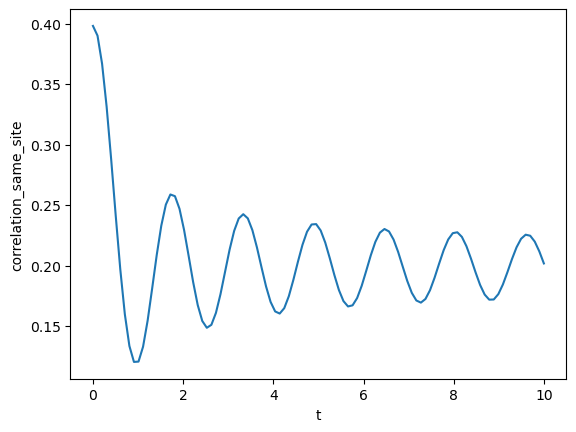

In [14]:
plt.plot(time,n1)

plt.xlabel("t")
plt.ylabel("correlation_same_site")


In [59]:
er = np.zeros((2500,2500))
er2 = er.reshape((50,50,50,50))

In [61]:
exp_term = np.exp(1j * (eigval[:, None] + eigval[None, :] - eigval[:, None] - eigval[None, :]))

In [62]:
exp_term.shape

(50, 50)

In [ ]:
import numpy as np
from tqdm import tqdm

# Define time and initialize n1
time = np.linspace(0, 50, 100)
n1 = np.zeros((10, len(time)), dtype=np.complex128)  # Ensure complex numbers for the result

# Precompute dot products involving 'site' and 'eigvec'
dot_eigvec_site0 = np.dot(eigvec.T, site[:, 0])  # Shape (50,)
dot_site_j_eigvec = np.dot(site.T, eigvec)       # Shape (50, 50)

# Loop over t1
for t1 in range(10):
    for t in tqdm(range(len(time))):
        sum_result = 0
        
        # Precompute the exponential terms for the current time step
        # Use element-wise multiplication to compute the complex exponential
        for j in range(50):
            A = dot_eigvec_site0 * dot_site_j_eigvec[j]  # Vector of length 50 (one for each alpha)
            B = dot_site_j_eigvec[j].conj() * dot_eigvec_site0.conj()  # Vector of length 50 (for beta)
            
            # Compute the exponential for each combination of alpha and beta
            exp_term = np.exp(1j * (eigval[:, None] - eigval[None, :]) * time[t])  # (50, 50) matrix
            
            # Sum over alpha and beta using vectorized numpy operations
            sum_result += np.sum(A[:, None] * B[None, :] * exp_term) * neel[j]
        
        n1[t1, t] = sum_result
